# Laboratório II · Ecossistema: Ethereum, altcoins e stablecoins
*Bitcoin na Veia: do halving ao ETF*, 2ª edição, Flávio Lemos, CMT

Dados até **30/09/2026**. O laboratório compara o Ether com o Bitcoin (retorno, volatilidade, correlação, quedas e a razão ETH/BTC) mede os ETFs de Ether nos EUA e na B3 contra a moeda, refaz o top 20 de 2018, a febre de 2021, as stablecoins e o DeFi, faz a matemática da custódia, mede as quebras de 2022 e monta uma prova de reservas em miniatura. Serve aos Capítulos 5 a 8. O Capítulo 19 da *Análise Técnica dos Mercados Financeiros*, 4ª edição, usa a mesma base de dados.

In [ ]:
!pip install -q yfinance mnemonic

In [2]:
import logging
import os
import numpy as np
import pandas as pd
import yfinance as yf

logging.getLogger("yfinance").setLevel(logging.CRITICAL)
FIM = "2026-10-01"                      # dados até 30/09/2026
RAW = "https://raw.githubusercontent.com/traderbrasil/livro-bitcoin-na-veia/main/labs/dados/"
def baixa(nome):
    """Usa a cópia dos dados salva no GitHub do livro (mesmos números do livro); sem ela, baixa tudo de novo."""
    if not os.path.exists(nome):
        try:
            import urllib.request
            urllib.request.urlretrieve(RAW + nome, nome)
        except Exception:
            pass
    return os.path.exists(nome)
CACHE = "dados_lab2.pkl"
pc = lambda x, k=0: f"{x:.{k}%}".replace(".", ",")
ps = lambda x, k=0: ("+" if x >= 0 else "") + pc(x, k)
nr = lambda x, k=0: f"{x:,.{k}f}".replace(",", "X").replace(".", ",").replace("X", ".")
cr = lambda x: ("+" if x >= 0 else "") + f"{x:.2f}".replace(".", ",")
TICKERS = ["BTC-USD", "ETH-USD", "ETHA", "ETHE11.SA", "QETH11.SA", "BRL=X"]
TOP20_2018 = [  # Figura 3.1 da 1ª edição: CoinMarketCap, 11/01/2018 (preço em US$)
    ("Bitcoin", "BTC", 13451.40), ("Ethereum", "ETH", 1177.04), ("Ripple", "XRP", 2.02), ("Bitcoin Cash", "BCH", 2493.38),
    ("Cardano", "ADA", 0.712740), ("Litecoin", "LTC", 230.15), ("NEM", "XEM", 1.36), ("Stellar", "XLM", 0.572678),
    ("IOTA", "IOTA", 3.38), ("Dash", "DASH", 1013.97), ("TRON", "TRX", 0.110834), ("NEO", "NEO", 110.31),
    ("EOS", "EOS", 11.70), ("Monero", "XMR", 363.15), ("Bitcoin Gold", "BTG", 212.10), ("ICON", "ICX", 9.31),
    ("Qtum", "QTUM", 47.65), ("Ethereum Classic", "ETC", 33.39), ("RaiBlocks (hoje Nano)", "XNO", 24.36), ("Lisk", "LSK", 25.43)]
FEBRE = ["DOGE", "MANA", "SAND", "AXS"]
EXTRA = [f"{t}-USD" for _, t, _ in TOP20_2018] + [f"{m}-USD" for m in FEBRE] + ["USDT-USD", "USDC-USD", "USTC-USD", "LUNC-USD", "FTT-USD", "CEL-USD", "BNB-USD"]

if baixa(CACHE):
    D = pd.read_pickle(CACHE)
else:
    D = {"Close": yf.download(sorted(set(TICKERS + EXTRA)), start="2017-01-01", end=FIM, auto_adjust=True,
                              progress=False)["Close"]}
    import json, urllib.request
    def llama(url):
        for tentativa in range(5):
            try:
                return json.loads(urllib.request.urlopen(url, timeout=60).read())
            except Exception:
                if tentativa == 4:
                    raise
    st = llama("https://stablecoins.llama.fi/stablecoincharts/all")
    D["stable"] = pd.Series({pd.to_datetime(int(x["date"]), unit="s"): x["totalCirculatingUSD"].get("peggedUSD", 0)
                             for x in st}).loc[:"2026-09-30"]
    tv = llama("https://api.llama.fi/v2/historicalChainTvl")
    D["tvl"] = pd.Series({pd.to_datetime(int(x["date"]), unit="s"): x["tvl"] for x in tv}).loc[:"2026-09-30"]
    pd.to_pickle(D, CACHE)
C = D["Close"]
btc = C["BTC-USD"].dropna(); eth = C["ETH-USD"].dropna()
btc, eth = btc[btc > 0], eth[eth > 0]

## Parte 1: Ether contra Bitcoin

In [3]:
ini = eth.index[0]
print(f"Parte 1a. De {ini:%d/%m/%Y} (início da série do Yahoo) a {eth.index[-1]:%d/%m/%Y}")
for nome, s_ in [("Bitcoin", btc.loc[ini:]), ("Ether", eth)]:
    print(f"   {nome:<8} US$ {nr(s_.iloc[0], 2)} -> US$ {nr(s_.iloc[-1], 2)} ({ps(s_.iloc[-1] / s_.iloc[0] - 1)});"
          f" máxima US$ {nr(s_.max(), 2)} em {s_.idxmax():%d/%m/%Y}")
R = pd.DataFrame({"btc": btc, "eth": eth}).dropna()
R = R[R.index.dayofweek < 5].pct_change().dropna()       # dias úteis, como no Laboratório I
TAB_ETH = []
print("\nParte 1b. Volatilidade anualizada (dias úteis) e correlação diária Ether x Bitcoin, por ano")
print("   ano   Ether  Bitcoin  correlação")
for ano in range(2018, 2027):
    x = R.loc[str(ano)]
    v = x.std() * np.sqrt(252)
    TAB_ETH.append((ano, v["eth"], v["btc"], x["eth"].corr(x["btc"])))
    print(f"   {ano}  {pc(v['eth']):>5}  {pc(v['btc']):>7}  {cr(x['eth'].corr(x['btc'])):>10}")
print("   (2026 vai até 30/09)")

Parte 1a. De 09/11/2017 (início da série do Yahoo) a 30/09/2026
   Bitcoin  US$ 7.143,58 -> US$ 83.553,85 (+1070%); máxima US$ 124.752,53 em 06/10/2025
   Ether    US$ 320,88 -> US$ 2.683,68 (+736%); máxima US$ 4.831,35 em 22/08/2025

Parte 1b. Volatilidade anualizada (dias úteis) e correlação diária Ether x Bitcoin, por ano
   ano   Ether  Bitcoin  correlação
   2018   105%      76%       +0,76
   2019    75%      68%       +0,80
   2020    95%      71%       +0,85
   2021   107%      78%       +0,72
   2022    86%      63%       +0,90
   2023    49%      46%       +0,85
   2024    66%      56%       +0,82
   2025    70%      39%       +0,81
   2026    60%      44%       +0,91
   (2026 vai até 30/09)


In [4]:
RAZAO = (eth / btc).dropna()
print(f"Parte 1c. Razão ETH/BTC: {nr(RAZAO.iloc[0], 4)} em {RAZAO.index[0]:%d/%m/%Y};"
      f" máxima {nr(RAZAO.max(), 4)} em {RAZAO.idxmax():%d/%m/%Y}; {nr(RAZAO.iloc[-1], 4)} em {RAZAO.index[-1]:%d/%m/%Y}")
print(f"   Na data do The Merge (15/09/2022): {nr(RAZAO.loc['2022-09-15'], 4)}")
QUEDAS = []
print("\nParte 1d. Grandes quedas do Ether (fechamento diário em dólar)")
for nome, a, b in [("2018", "2017-11-01", "2019-06-30"), ("2021-2022", "2021-04-01", "2023-01-31"),
                   ("2024-2025", "2024-01-01", "2025-06-30"), ("2025-2026", "2025-07-01", "2026-09-30")]:
    x = eth.loc[a:b]; topo = x.idxmax(); fundo = x.loc[topo:].idxmin()
    QUEDAS.append((nome, topo, x[topo], fundo, x[fundo], x[fundo] / x[topo] - 1))
    print(f"   {nome}: US$ {nr(x[topo])} ({topo:%d/%m/%Y}) -> US$ {nr(x[fundo])} ({fundo:%d/%m/%Y}): {pc(x[fundo] / x[topo] - 1)}")

Parte 1c. Razão ETH/BTC: 0,0449 em 09/11/2017; máxima 0,1131 em 01/02/2018; 0,0321 em 30/09/2026
   Na data do The Merge (15/09/2022): 0,0747

Parte 1d. Grandes quedas do Ether (fechamento diário em dólar)
   2018: US$ 1.396 (13/01/2018) -> US$ 84 (14/12/2018): -94%
   2021-2022: US$ 4.812 (08/11/2021) -> US$ 994 (18/06/2022): -79%
   2024-2025: US$ 4.066 (11/03/2024) -> US$ 1.473 (08/04/2025): -64%
   2025-2026: US$ 4.831 (22/08/2025) -> US$ 1.565 (25/06/2026): -68%


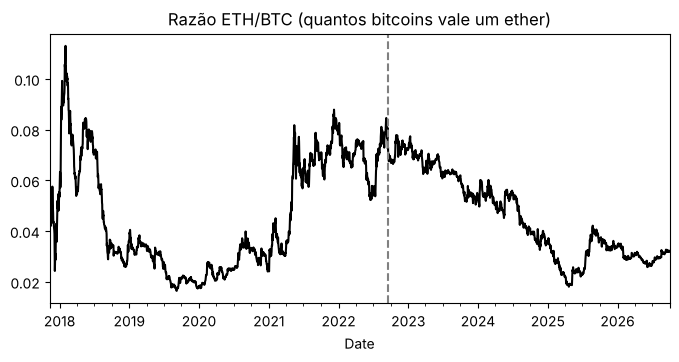

In [5]:
import matplotlib.pyplot as plt
ax = RAZAO.plot(figsize=(8, 3.5), color="black", title="Razão ETH/BTC (quantos bitcoins vale um ether)")
ax.axvline(pd.Timestamp("2022-09-15"), color="gray", ls="--")
plt.show()

## Parte 2: ETFs de Ether contra a moeda

In [6]:
BRL = C["BRL=X"].dropna()
ETH_BRL = (eth * BRL.reindex(eth.index).ffill()).dropna()
TAB_ETF = []
print("Parte 2. Produtos regulados contra a moeda (retornos diários nos dias em que os dois têm preço)")
for etf, ref, nome in [("ETHA", eth, "ETHA (EUA) x Ether em dólar"), ("ETHE11.SA", ETH_BRL, "ETHE11 (B3) x Ether em reais"),
                       ("QETH11.SA", ETH_BRL, "QETH11 (B3) x Ether em reais")]:
    dd = pd.DataFrame({"e": C[etf], "b": ref}).dropna()
    r = dd.pct_change().dropna()
    te, tb = dd["e"].iloc[-1] / dd["e"].iloc[0] - 1, dd["b"].iloc[-1] / dd["b"].iloc[0] - 1
    TAB_ETF.append((nome, dd.index[0], r["e"].corr(r["b"]), te, tb))
    print(f"   {nome:<30} desde {dd.index[0]:%d/%m/%Y}: correlação {nr(r['e'].corr(r['b']), 2)} | produto {ps(te)}"
          f" x moeda {ps(tb)} | diferença {ps(te - tb, 1)}")

Parte 2. Produtos regulados contra a moeda (retornos diários nos dias em que os dois têm preço)
   ETHA (EUA) x Ether em dólar    desde 23/07/2024: correlação 0,91 | produto -23% x moeda -23% | diferença -0,4%
   ETHE11 (B3) x Ether em reais   desde 17/08/2021: correlação 0,85 | produto -20% x moeda -12% | diferença -8,5%
   QETH11 (B3) x Ether em reais   desde 03/08/2021: correlação 0,82 | produto +1% x moeda +8% | diferença -7,3%


## Parte 3: o que sobrou do top 20 de 11/01/2018

In [7]:
FIG = []
b0, b1 = 13451.40, btc.iloc[-1]
print(f"Parte 3. As 20 maiores de 11/01/2018 (Figura 3.1 da 1ª edição) em 30/09/2026 (Yahoo Finance)")
print("    #  moeda                    US$ em 11/01/2018  US$ em 30/09/2026   em dólar  em bitcoins")
for i, (nome, t, p0) in enumerate(TOP20_2018, 1):
    s_ = C[f"{t}-USD"].dropna()
    p1 = s_.iloc[-1]
    FIG.append((i, nome, t, p0, p1, p1 / p0 - 1, (p1 / b1) / (p0 / b0) - 1))
    print(f"   {i:>2}  {nome:<23} {nr(p0, 4 if p0 < 1 else 2):>17}  {nr(p1, 4 if p1 < 1 else 2):>17}"
          f"  {pc(p1 / p0 - 1):>8}  {pc((p1 / b1) / (p0 / b0) - 1):>10}")
F = pd.DataFrame(FIG, columns=["n", "nome", "t", "p0", "p1", "usd", "btc"]).iloc[1:]
print(f"\n   Das 19 alternativas ao Bitcoin: {(F['usd'] > 0).sum()} subiram em dólar; {(F['btc'] > 0).sum()} bateram o Bitcoin;"
      f" {(F['usd'] < -0.9).sum()} perderam mais de 90% em dólar; mediana em dólar {pc(F['usd'].median())}")
print("   Preço não é valor de mercado: várias moedas emitiram muitas unidades novas desde 2018.")

Parte 3. As 20 maiores de 11/01/2018 (Figura 3.1 da 1ª edição) em 30/09/2026 (Yahoo Finance)
    #  moeda                    US$ em 11/01/2018  US$ em 30/09/2026   em dólar  em bitcoins
    1  Bitcoin                         13.451,40          83.553,85      521%          0%
    2  Ethereum                         1.177,04           2.683,68      128%        -63%
    3  Ripple                               2,02               1,49      -26%        -88%
    4  Bitcoin Cash                     2.493,38             305,88      -88%        -98%
    5  Cardano                            0,7127             0,2466      -65%        -94%
    6  Litecoin                           230,15              67,17      -71%        -95%
    7  NEM                                  1,36             0,0006     -100%       -100%
    8  Stellar                            0,5727             0,2263      -60%        -94%
    9  IOTA                                 3,38             0,0536      -98%       -100%
   1

## Parte 4: a febre de 2021

In [8]:
TAB_FEBRE = []
print("Parte 4. A febre de 2021: do pico de 2021 até 30/09/2026")
for m in ["BTC", "ETH"] + FEBRE:
    s_ = C[f"{m}-USD"].dropna(); s_ = s_[s_ > 0]
    pico = s_.loc["2021"].idxmax()
    TAB_FEBRE.append((m, pico, s_[pico], s_.iloc[-1], s_.iloc[-1] / s_[pico] - 1))
    print(f"   {m:<5} pico de 2021 em {pico:%d/%m/%Y} (US$ {nr(s_[pico], 4 if s_[pico] < 1 else 2)}) | hoje"
          f" US$ {nr(s_.iloc[-1], 4 if s_.iloc[-1] < 1 else 2)} | {ps(s_.iloc[-1] / s_[pico] - 1)}")

Parte 4. A febre de 2021: do pico de 2021 até 30/09/2026
   BTC   pico de 2021 em 08/11/2021 (US$ 67.566,83) | hoje US$ 83.553,85 | +24%
   ETH   pico de 2021 em 08/11/2021 (US$ 4.812,09) | hoje US$ 2.683,68 | -44%
   DOGE  pico de 2021 em 07/05/2021 (US$ 0,6848) | hoje US$ 0,0945 | -86%
   MANA  pico de 2021 em 25/11/2021 (US$ 5,48) | hoje US$ 0,0898 | -98%
   SAND  pico de 2021 em 25/11/2021 (US$ 8,40) | hoje US$ 0,0438 | -99%
   AXS   pico de 2021 em 07/11/2021 (US$ 160,36) | hoje US$ 1,16 | -99%


## Parte 5: stablecoins e DeFi

In [9]:
print("Parte 5a. Quanto as stablecoins se afastaram de US$ 1 (fechamento diário)")
for t in ["USDT-USD", "USDC-USD"]:
    s_ = C[t].dropna()
    print(f"   {t[:4]}: mínima US$ {nr(s_.min(), 4)} em {s_.idxmin():%d/%m/%Y}; máxima US$ {nr(s_.max(), 4)} em"
          f" {s_.idxmax():%d/%m/%Y}; dias fora de 0,99 a 1,01: {((s_ < 0.99) | (s_ > 1.01)).sum()}")
ust, luna = C["USTC-USD"].dropna(), C["LUNC-USD"].dropna()
print(f"   TerraUSD (UST): US$ {nr(ust.loc['2022-05-01'], 4)} em 01/05/2022, US$ {nr(ust.loc['2022-05-31'], 4)} em 31/05/2022,"
      f" US$ {nr(ust.iloc[-1], 4)} em 30/09/2026")
print(f"   Luna: máxima US$ {nr(luna.max(), 2)} em {luna.idxmax():%d/%m/%Y}; US$ {nr(luna.loc['2022-05-31'], 6)} em 31/05/2022")
ST, TV = D["stable"], D["tvl"]
print("\nParte 5b. Stablecoins em dólar em circulação e valor travado em DeFi (DefiLlama), em US$ bilhões")
for d in ["2020-01-01", "2021-11-09", "2022-05-01", "2022-12-31", "2024-12-31", "2026-09-30"]:
    print(f"   {pd.Timestamp(d):%d/%m/%Y}: stablecoins {nr(ST.loc[:d].iloc[-1] / 1e9, 1):>6} | DeFi {nr(TV.loc[:d].iloc[-1] / 1e9, 1):>6}")
print(f"   Máxima do valor travado em DeFi: US$ {nr(TV.max() / 1e9, 1)} bilhões em {TV.idxmax():%d/%m/%Y}")

Parte 5a. Quanto as stablecoins se afastaram de US$ 1 (fechamento diário)
   USDT: mínima US$ 0,9666 em 14/11/2018; máxima US$ 1,0779 em 12/12/2017; dias fora de 0,99 a 1,01: 138
   USDC: mínima US$ 0,9701 em 18/03/2020; máxima US$ 1,0440 em 30/01/2020; dias fora de 0,99 a 1,01: 178
   TerraUSD (UST): US$ 1,0016 em 01/05/2022, US$ 0,0214 em 31/05/2022, US$ 0,0058 em 30/09/2026
   Luna: máxima US$ 116,41 em 04/04/2022; US$ 0,000115 em 31/05/2022

Parte 5b. Stablecoins em dólar em circulação e valor travado em DeFi (DefiLlama), em US$ bilhões
   01/01/2020: stablecoins    4,2 | DeFi    0,6
   09/11/2021: stablecoins  137,1 | DeFi  177,5
   01/05/2022: stablecoins  187,1 | DeFi  135,8
   31/12/2022: stablecoins  137,5 | DeFi   38,3
   31/12/2024: stablecoins  203,8 | DeFi  115,9
   30/09/2026: stablecoins  306,3 | DeFi   95,4
   Máxima do valor travado em DeFi: US$ 177,5 bilhões em 09/11/2021


## Parte 5c e 5d: empréstimos descentralizados, Aave e Compound (Capítulo 6)

In [10]:
ECACHE = "dados_lab2_emprestimos.pkl"
if baixa(ECACHE):
    EMP = pd.read_pickle(ECACHE)
else:
    import json, urllib.request
    EMP = {}
    for p in ["aave", "compound-finance"]:
        d = json.loads(urllib.request.urlopen(f"https://api.llama.fi/protocol/{p}", timeout=90).read())
        dep = pd.Series({pd.to_datetime(int(x["date"]), unit="s"): x["totalLiquidityUSD"] for x in d["tvl"]})
        emp = pd.Series({pd.to_datetime(int(x["date"]), unit="s"): x["totalLiquidityUSD"] for x in d["chainTvls"]["borrowed"]["tvl"]})
        EMP[p] = pd.DataFrame({"depositado": dep, "emprestado": emp}).loc[:"2026-09-30"]
    pd.to_pickle(EMP, ECACHE)
print("Parte 5c. Aave e Compound no DefiLlama, em US$ bilhões (valor depositado líquido e valor emprestado)")
for p, nome in [("aave", "Aave"), ("compound-finance", "Compound")]:
    x = EMP[p].dropna(how="all"); dep = x["depositado"].dropna(); emp = x["emprestado"].dropna()
    print(f"   {nome:<9} máxima depositada {nr(dep.max() / 1e9, 1)} em {dep.idxmax():%d/%m/%Y} | 30/09/2026: depositado {nr(dep.iloc[-1] / 1e9, 1)}, emprestado {nr(emp.iloc[-1] / 1e9, 1)}")
print("   A Compound abriu o caminho em 2018 e liderou em 2021; em 2026, o Aave era mais de dez vezes maior.")

LIMITE = 0.80        # limite de liquidação hipotético para o ether como garantia (cada protocolo vota o seu)
BONUS = 0.05         # desconto hipotético que o liquidante recebe sobre a garantia
e = eth.loc["2017-11-09":]
print(f"\nParte 5d. Depositar ether e tomar dólares emprestados: com que queda o empréstimo é liquidado? (limite de {pc(LIMITE)})")
for ltv in [0.25, 0.40, 0.50, 0.60, 0.70]:
    queda = 1 - ltv / LIMITE
    freq = {}
    for dias in (30, 90):
        minimo = e[::-1].rolling(dias + 1, min_periods=dias + 1).min()[::-1]      # menor preço nos próximos dias
        ok = minimo.notna()
        freq[dias] = ((minimo[ok] / e[ok] - 1) <= -queda).mean()
    print(f"   Emprestado {pc(ltv):>4} da garantia → liquida com queda de {pc(queda, 1):>5} | aconteceu em {pc(freq[30], 1):>5} das janelas de 30 dias"
          f" e em {pc(freq[90], 1):>5} das de 90 dias (ether, 2017 a 2026)")
print(f"   Na liquidação, o liquidante paga parte da dívida e leva a garantia com desconto de {pc(BONUS)}: é a multa de quem foi liquidado.")
print("   Tomar dólares contra ether para comprar mais ether é alavancagem, igual à do Capítulo 10, sem a bolsa no meio.")

Parte 5c. Aave e Compound no DefiLlama, em US$ bilhões (valor depositado líquido e valor emprestado)
   Aave      máxima depositada 45,8 em 07/10/2025 | 30/09/2026: depositado 19,1, emprestado 13,1
   Compound  máxima depositada 12,3 em 09/11/2021 | 30/09/2026: depositado 1,6, emprestado 0,7
   A Compound abriu o caminho em 2018 e liderou em 2021; em 2026, o Aave era mais de dez vezes maior.

Parte 5d. Depositar ether e tomar dólares emprestados: com que queda o empréstimo é liquidado? (limite de 80%)
   Emprestado  25% da garantia → liquida com queda de 68,8% | aconteceu em  0,0% das janelas de 30 dias e em  0,7% das de 90 dias (ether, 2017 a 2026)
   Emprestado  40% da garantia → liquida com queda de 50,0% | aconteceu em  1,6% das janelas de 30 dias e em 12,2% das de 90 dias (ether, 2017 a 2026)
   Emprestado  50% da garantia → liquida com queda de 37,5% | aconteceu em  6,5% das janelas de 30 dias e em 23,9% das de 90 dias (ether, 2017 a 2026)
   Emprestado  60% da garantia → liquida

## Parte 6: a matemática da custódia

In [11]:
from math import comb
from mnemonic import Mnemonic
print("Parte 6a. A frase-semente (BIP39). NUNCA digite aqui a sua frase real: use só os exemplos.")
pt = Mnemonic("portuguese"); en = Mnemonic("english")
print(f"   Lista de palavras: {len(en.wordlist)} (há versão em português, também com {len(pt.wordlist)})")
H_REDE = 9.45e20                         # hashes por segundo de toda a rede do Bitcoin (Laboratório I, set/2026)
for n, bits in [(12, 128), (24, 256)]:
    anos = 2 ** bits / H_REDE / (365.25 * 24 * 3600)
    print(f"   {n} palavras: {bits} bits de aleatoriedade, 2^{bits} combinações; testando no ritmo de toda a rede"
          f" do Bitcoin, {anos:.1e} anos".replace(".", ","))
teste = en.to_mnemonic(bytes(16))        # vetor de teste oficial da BIP39 (entropia zero), sem valor nenhum
print(f"   Frase de teste da BIP39: '{teste}' -> válida? {en.check(teste)}")
troca = teste.replace("about", "abandon")
print(f"   Trocando a última palavra: válida? {en.check(troca)} (a última palavra carrega um dígito de controle)")
s1, s2 = en.to_seed(teste, "").hex()[:16], en.to_seed(teste, "senha extra").hex()[:16]
print(f"   Mesma frase, sem e com senha adicional (passphrase): semente {s1}... x {s2}... (carteiras diferentes)")

Parte 6a. A frase-semente (BIP39). NUNCA digite aqui a sua frase real: use só os exemplos.
   Lista de palavras: 2048 (há versão em português, também com 2048)
   12 palavras: 128 bits de aleatoriedade, 2^128 combinações; testando no ritmo de toda a rede do Bitcoin, 1,1e+10 anos
   24 palavras: 256 bits de aleatoriedade, 2^256 combinações; testando no ritmo de toda a rede do Bitcoin, 3,9e+48 anos
   Frase de teste da BIP39: 'abandon abandon abandon abandon abandon abandon abandon abandon abandon abandon abandon about' -> válida? True
   Trocando a última palavra: válida? False (a última palavra carrega um dígito de controle)
   Mesma frase, sem e com senha adicional (passphrase): semente 5eb00bbddcf06908... x 820f9008cb90923f... (carteiras diferentes)


In [12]:
P_PERDA, P_ROUBO, ANOS = 0.05, 0.02, 10   # hipóteses: chance anual de perder ou de ter copiada cada chave
def prob_ao_menos(k, n, p):
    return sum(comb(n, i) * p ** i * (1 - p) ** (n - i) for i in range(k, n + 1))
TAB_MULTI = []
print(f"\nParte 6b. Perder ou ser roubado? Hipóteses: cada chave tem {pc(P_PERDA)} ao ano de chance de se perder e"
      f" {pc(P_ROUBO)} de ser copiada, de forma independente")
print("   arranjo        perder o acesso em 1 ano  ser roubado em 1 ano | em 10 anos: perder  roubar")
for m, n in [(1, 1), (2, 2), (2, 3), (3, 5)]:
    perde = prob_ao_menos(n - m + 1, n, P_PERDA)      # perde se sobrarem menos de m chaves
    rouba = prob_ao_menos(m, n, P_ROUBO)              # roubado se o ladrão juntar m chaves
    p10 = prob_ao_menos(n - m + 1, n, 1 - (1 - P_PERDA) ** ANOS)
    r10 = prob_ao_menos(m, n, 1 - (1 - P_ROUBO) ** ANOS)
    TAB_MULTI.append((f"{m} de {n}", perde, rouba, p10, r10))
    print(f"   {m} de {n:<10} {pc(perde, 2):>24}  {pc(rouba, 3):>20} | {pc(p10, 1):>18}  {pc(r10, 2):>6}")
print("   Chaves exigidas protegem contra roubo; chaves de reserva protegem contra perda. Sem revisão, o risco de perda"
      " cresce com os anos: teste as chaves e troque a que sumir, todo ano.")


Parte 6b. Perder ou ser roubado? Hipóteses: cada chave tem 5% ao ano de chance de se perder e 2% de ser copiada, de forma independente
   arranjo        perder o acesso em 1 ano  ser roubado em 1 ano | em 10 anos: perder  roubar
   1 de 1                             5,00%                2,000% |              40,1%  18,29%
   2 de 2                             9,75%                0,040% |              64,2%   3,35%
   2 de 3                             0,73%                0,118% |              35,4%   8,81%
   3 de 5                             0,12%                0,008% |              32,0%   4,56%
   Chaves exigidas protegem contra roubo; chaves de reserva protegem contra perda. Sem revisão, o risco de perda cresce com os anos: teste as chaves e troque a que sumir, todo ano.


## Parte 7: quebras de 2022 e os tokens das empresas

In [13]:
TAB_QUEBRA = []
print("Parte 7a. O Bitcoin nas três quebras de 2022 (fechamento diário em dólar)")
for nome, a, b in [("Terra/Luna", "2022-05-06", "2022-06-18"), ("Celsius", "2022-06-10", "2022-06-18"),
                   ("FTX", "2022-11-06", "2022-11-21")]:
    x = btc.loc[a:b]
    TAB_QUEBRA.append((nome, a, x.iloc[0], x.idxmin(), x.min(), x.min() / x.iloc[0] - 1))
    print(f"   {nome:<11} {pd.Timestamp(a):%d/%m/%Y}: US$ {nr(x.iloc[0])} -> mínima US$ {nr(x.min())} em {x.idxmin():%d/%m/%Y}"
          f" ({pc(x.min() / x.iloc[0] - 1)})")
print("\nParte 7b. O token da própria empresa (fechamento diário em dólar)")
for t, nome, a, b in [("FTT-USD", "FTT (FTX)", "2022-11-05", "2022-11-12"), ("CEL-USD", "CEL (Celsius)", "2022-06-01", "2022-06-13"),
                      ("BNB-USD", "BNB (Binance)", "2022-11-05", "2022-11-12")]:
    x = C[t].dropna()
    print(f"   {nome:<14} {pd.Timestamp(a):%d/%m/%Y}: US$ {nr(x.loc[a], 2)} | {pd.Timestamp(b):%d/%m/%Y}: US$ {nr(x.loc[b], 2)}"
          f" ({pc(x.loc[b] / x.loc[a] - 1)}) | 30/09/2026: US$ {nr(x.iloc[-1], 4)} ({ps(x.iloc[-1] / x.loc[a] - 1)})")
print("   Token emitido pela própria corretora vira garantia de si mesma: quando a confiança cai, o token e a empresa caem juntos.")

Parte 7a. O Bitcoin nas três quebras de 2022 (fechamento diário em dólar)
   Terra/Luna  06/05/2022: US$ 36.041 -> mínima US$ 19.018 em 18/06/2022 (-47%)
   Celsius     10/06/2022: US$ 29.084 -> mínima US$ 19.018 em 18/06/2022 (-35%)
   FTX         06/11/2022: US$ 20.926 -> mínima US$ 15.787 em 21/11/2022 (-25%)

Parte 7b. O token da própria empresa (fechamento diário em dólar)
   FTT (FTX)      05/11/2022: US$ 24,06 | 12/11/2022: US$ 2,09 (-91%) | 30/09/2026: US$ 0,2522 (-99%)
   CEL (Celsius)  01/06/2022: US$ 0,71 | 13/06/2022: US$ 0,28 (-61%) | 30/09/2026: US$ 0,0061 (-99%)
   BNB (Binance)  05/11/2022: US$ 349,25 | 12/11/2022: US$ 282,34 (-19%) | 30/09/2026: US$ 768,1816 (+120%)
   Token emitido pela própria corretora vira garantia de si mesma: quando a confiança cai, o token e a empresa caem juntos.


In [14]:
import hashlib
print("Parte 7c. Prova de reservas em miniatura: árvore de Merkle com soma")
def h(*partes):
    return hashlib.sha256("|".join(str(p) for p in partes).encode()).hexdigest()
# clientes fictícios: (identificador anônimo, saldo em BTC)
CLIENTES = [("c1", 0.50), ("c2", 1.20), ("c3", 0.05), ("c4", 3.00), ("c5", 0.75), ("c6", 0.10), ("c7", 2.40), ("c8", 0.00)]
def folhas(cl):
    return [(h(i, s), s) for i, s in cl]
def sobe(nivel):
    if len(nivel) % 2: nivel = nivel + [(h("vazio"), 0.0)]
    return [(h(a[0], b[0], round(a[1] + b[1], 8)), round(a[1] + b[1], 8)) for a, b in zip(nivel[0::2], nivel[1::2])]
def raiz(cl):
    n = folhas(cl)
    while len(n) > 1: n = sobe(n)
    return n[0]
def caminho(cl, idx):
    n, prova = folhas(cl), []
    while len(n) > 1:
        if len(n) % 2: n = n + [(h("vazio"), 0.0)]
        irmao = idx ^ 1
        prova.append((n[irmao], "dir" if irmao > idx else "esq"))
        n, idx = sobe(n), idx // 2
    return prova
def confere(cliente, prova, raiz_publicada):
    atual = (h(*cliente), cliente[1])
    for (hh, ss), lado in prova:
        a, b = (atual, (hh, ss)) if lado == "dir" else ((hh, ss), atual)
        atual = (h(a[0], b[0], round(a[1] + b[1], 8)), round(a[1] + b[1], 8))
    return atual == raiz_publicada
R = raiz(CLIENTES)
print(f"   raiz publicada: {R[0][:16]}...  passivo total com clientes: {nr(R[1], 2)} BTC")
print(f"   o cliente c3 confere a sua inclusão com {len(caminho(CLIENTES, 2))} hashes: {confere(CLIENTES[2], caminho(CLIENTES, 2), R)}")
RESERVA = 8.20   # BTC em endereços que a corretora prova controlar (assinatura de mensagem)
print(f"   reservas provadas: {nr(RESERVA, 2)} BTC | reservas / passivo = {pc(RESERVA / R[1], 1)}")
TRUQUE = [c for c in CLIENTES if c[0] != "c4"]   # a corretora esconde o maior cliente
R2 = raiz(TRUQUE)
print(f"   com o truque de esconder c4: passivo cai para {nr(R2[1], 2)} BTC e a razão vira {pc(RESERVA / R2[1], 1)}")
print(f"   mas c4 não acha o próprio saldo na árvore nova: {confere(CLIENTES[3], caminho(CLIENTES, 3), R2)}")
print("   Lição: a prova só funciona se os clientes conferirem. E ela não mostra dívidas fora da árvore nem moedas emprestadas no dia da foto.")

Parte 7c. Prova de reservas em miniatura: árvore de Merkle com soma
   raiz publicada: 778c123cc3023be1...  passivo total com clientes: 8,00 BTC
   o cliente c3 confere a sua inclusão com 3 hashes: True
   reservas provadas: 8,20 BTC | reservas / passivo = 102,5%
   com o truque de esconder c4: passivo cai para 5,00 BTC e a razão vira 164,0%
   mas c4 não acha o próprio saldo na árvore nova: False
   Lição: a prova só funciona se os clientes conferirem. E ela não mostra dívidas fora da árvore nem moedas emprestadas no dia da foto.


In [15]:
print("Parte 7d. Custo total de uma compra: taxa + ágio sobre o preço de referência + saque")
BTC_BRL = btc.iloc[-1] * BRL.iloc[-1]
print(f"   bitcoin em 30/09/2026: R$ {nr(BTC_BRL)} (preço em dólar x dólar no Yahoo Finance)")
VALOR = 10_000   # R$ da compra
CORRETORAS = [("A, 'taxa zero'", 0.000, 0.010, 0.0002), ("B", 0.002, 0.001, 0.0002), ("C", 0.005, 0.002, 0.0000)]
for nome, taxa, agio, saque_btc in CORRETORAS:
    custo = VALOR * (taxa + agio) + saque_btc * BTC_BRL
    print(f"   {nome:<16} taxa {pc(taxa, 1)} + ágio {pc(agio, 1)} + saque {nr(saque_btc, 4)} BTC = R$ {nr(custo, 2)} ({pc(custo / VALOR, 2)} da compra)")
print("   Troque pelos números da sua corretora. O ágio é a distância entre o preço que ela cobra e um índice de referência no mesmo minuto.")

Parte 7d. Custo total de uma compra: taxa + ágio sobre o preço de referência + saque
   bitcoin em 30/09/2026: R$ 434.722 (preço em dólar x dólar no Yahoo Finance)
   A, 'taxa zero'   taxa 0,0% + ágio 1,0% + saque 0,0002 BTC = R$ 186,94 (1,87% da compra)
   B                taxa 0,2% + ágio 0,1% + saque 0,0002 BTC = R$ 116,94 (1,17% da compra)
   C                taxa 0,5% + ágio 0,2% + saque 0,0000 BTC = R$ 70,00 (0,70% da compra)
   Troque pelos números da sua corretora. O ágio é a distância entre o preço que ela cobra e um índice de referência no mesmo minuto.


## Para ir além
1. Na Parte 1b, calcule a correlação em janelas de 90 dias. Em que momentos o Ether se descolou do Bitcoin?
2. Na Parte 1c, a razão ETH/BTC subiu ou caiu depois do The Merge? E depois da estreia dos ETFs de Ether, em 23/07/2024?
3. Na Parte 2, a diferença entre ETF e moeda é maior ou menor que a taxa de administração anual do fundo?
4. Na Parte 3, troque o preço pelo valor de mercado. Quantas moedas do top 20 de 2018 ainda estão entre as 20 maiores?
5. Na Parte 5, em quais semanas o USDT e o USDC saíram da faixa de 0,99 a 1,01? O que aconteceu no mercado nesses dias?
6. Na Parte 6b, troque as hipóteses de perda e de roubo pelas suas. Qual arranjo minimiza o pior dos dois riscos?
7. Na Parte 7, compare a queda do Bitcoin com a do ether e com a do token de cada empresa nas mesmas janelas.
8. Na Parte 7c, acrescente um cliente e veja quantos hashes ele precisa para conferir a inclusão. Na Parte 7d, ache o valor de compra em que a corretora A deixa de ser a mais cara.
9. Na Parte 5d, troque o ether pelo bitcoin (BTC-USD) como garantia. Com 50% emprestados, a liquidação fica mais rara?

**Governança:** os resultados valem só para os dados e as datas usadas. Mudar regras até o resultado ficar bonito é sobreajuste (*overfitting*): a regra decora o passado e falha no futuro.

━━━━━━━━━━━━━━━━━━━━━━━

⚠️ AVISO LEGAL (DISCLAIMER):

━━━━━━━━━━━━━━━━━━━━━━━

Todo o conteúdo deste livro  é estritamente educacional e informativo. 

Não constitui, em nenhuma hipótese, recomendação de compra ou venda de ativos financeiros. 

Testes passados não são garantias de resultados futuros.

Investimentos envolvem riscos, incluindo a perda total do capital investido. 

Consulte sempre um profissional habilitado antes de tomar qualquer decisão de investimento.